In [1]:
import os
import glob
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from konlpy.tag import Mecab
from scipy import sparse
from tqdm import tqdm

# ---------------------------------------------------------
# 1. 설정 및 데이터 로드
# ---------------------------------------------------------
mecab = Mecab(dicpath='/opt/homebrew/lib/mecab/dic/mecab-ko-dic')
TARGET_DIRS = ["data/대법원_판례_txt화", "data/법률_정제_완료_txt화"]
OUTPUT_FILE = "legal_stopword_analysis_final.csv"

def get_corpus_list(target_dirs):
    corpus = []
    files = []
    for d in target_dirs:
        files.extend(glob.glob(os.path.join(d, "**", "*.txt"), recursive=True))
    
    print(f"총 {len(files)}개의 문서 로딩 및 전처리 시작...")
    
    for file_path in tqdm(files):
        try:
            with open(file_path, 'r', encoding='utf-8') as f:
                content = f.read()
            # 인코딩 오류 시 cp949 시도 등 예외처리는 생략 (필요 시 추가)
        except:
            continue
            
        # 명사(N), 용언(V)만 추출 (조사/어미 제외)
        tokens = []
        try:
            for word, pos in mecab.pos(content):
                if pos.startswith('N') or pos.startswith('V'):
                    tokens.append(word)
        except:
            continue
            
        if tokens:
            corpus.append(" ".join(tokens))
            
    return corpus

# 실행
print(">>> 데이터 로딩 중...")
corpus_data = get_corpus_list(TARGET_DIRS)
print(f"전처리 완료된 문서 수: {len(corpus_data)}")

if len(corpus_data) == 0:
    print("[Error] 처리할 문서가 없습니다. 경로를 확인해주세요.")
    exit()

# ---------------------------------------------------------
# 2. DTM 생성 (Sparse Matrix)
# ---------------------------------------------------------
print(">>> DTM(Document-Term Matrix) 생성 중...")
# min_df=5: 5개 미만 문서에 등장한 희귀 단어는 분석에서 제외 (노이즈)
vectorizer = CountVectorizer(min_df=10) 
X = vectorizer.fit_transform(corpus_data)
feature_names = np.array(vectorizer.get_feature_names_out())
print(f"DTM 크기: {X.shape} (문서 수 x 단어 수)")

# ---------------------------------------------------------
# 3. Metric 1: TF-IDF (가중치)
# ---------------------------------------------------------
print(">>> 지표 1: TF-IDF 계산 중...")
tfidf_transformer = TfidfTransformer()
X_tfidf = tfidf_transformer.fit_transform(X)
# 평균 TF-IDF (낮을수록 불용어)
avg_tfidf = np.array(X_tfidf.mean(axis=0)).flatten()

# ---------------------------------------------------------
# 4. Metric 2: Entropy (무작위성)
# ---------------------------------------------------------
print(">>> 지표 2: Entropy 계산 중...")
# P(d|t) 계산
total_term_freq = np.array(X.sum(axis=0)).flatten()
inv_freq = 1.0 / total_term_freq
D_inv = sparse.diags(inv_freq)
P_dt = X @ D_inv  # Column Normalize

# Entropy: -Sum(P * log P)
# log(0) 방지를 위해 data 속성만 건드림
P_dt.data = P_dt.data * np.log(P_dt.data)
entropy_scores = -1 * np.array(P_dt.sum(axis=0)).flatten()

# ---------------------------------------------------------
# 5. Metric 3: MP-VP (평균 확률 & 분산)
# ---------------------------------------------------------
print(">>> 지표 3: MP-VP 계산 중...")
# P(t|d) = 문서 내 단어 빈도 / 문서 전체 단어 수
doc_lengths = np.array(X.sum(axis=1)).flatten()
doc_lengths[doc_lengths == 0] = 1 # div by zero 방지
D_inv_doc = sparse.diags(1.0 / doc_lengths)
P_td = D_inv_doc @ X  # Row Normalize

# MP (Mean Probability)
mp_scores = np.array(P_td.mean(axis=0)).flatten()

# VP (Variance of Probability) = E[X^2] - (E[X])^2
# 메모리 절약을 위해 Sparse 상태에서 제곱 계산
P_td_sq = P_td.copy()
P_td_sq.data **= 2
mean_sq = np.array(P_td_sq.mean(axis=0)).flatten()
vp_scores = mean_sq - (mp_scores ** 2)

# ---------------------------------------------------------
# 6. 결과 통합 및 정규화
# ---------------------------------------------------------
print(">>> 결과 정리 및 저장 중...")
df = pd.DataFrame({
    'word': feature_names,
    'count': total_term_freq,
    'tfidf': avg_tfidf,
    'entropy': entropy_scores,
    'mp': mp_scores,
    'vp': vp_scores
})

# Min-Max Normalization (0~1)
for col in ['tfidf', 'entropy', 'mp', 'vp']:
    df[f'norm_{col}'] = (df[col] - df[col].min()) / (df[col].max() - df[col].min())

# 불용어 점수 (Stopword Score) 계산
# 1. TF-IDF: 낮을수록 불용어 -> (1 - norm)
df['score_tfidf'] = 1 - df['norm_tfidf']
# 2. Entropy: 높을수록 불용어 -> (norm)
df['score_entropy'] = df['norm_entropy']
# 3. MP-VP: MP 높고 VP 낮을수록 불용어 -> norm_mp + (1 - norm_vp)
df['score_mpvp'] = df['norm_mp'] + (1 - df['norm_vp'])

df = df.round(4)

# 저장
df.sort_values('count', ascending=False).to_csv(OUTPUT_FILE, index=False, encoding='utf-8-sig')
print(f"완료! 파일 저장됨: {OUTPUT_FILE}")

# ---------------------------------------------------------
# 7. 상위 후보 미리보기
# ---------------------------------------------------------
top_n = 20
print(f"\n[각 지표별 Top {top_n} 불용어 후보]")
print("-" * 60)
print(f"{'Rank':<5} | {'TF-IDF (Low Value)':<20} | {'Entropy (High Value)':<20} | {'MP-VP (High Mean/Low Var)':<20}")
print("-" * 60)

top_tfidf = df.sort_values('score_tfidf', ascending=False).head(top_n)['word'].tolist()
top_entropy = df.sort_values('score_entropy', ascending=False).head(top_n)['word'].tolist()
top_mpvp = df.sort_values('score_mpvp', ascending=False).head(top_n)['word'].tolist()

for i in range(top_n):
    print(f"{i+1:<5} | {top_tfidf[i]:<20} | {top_entropy[i]:<20} | {top_mpvp[i]:<20}")

>>> 데이터 로딩 중...
총 7162개의 문서 로딩 및 전처리 시작...


100%|██████████| 7162/7162 [00:36<00:00, 194.06it/s]


전처리 완료된 문서 수: 7162
>>> DTM(Document-Term Matrix) 생성 중...
DTM 크기: (7162, 11499) (문서 수 x 단어 수)
>>> 지표 1: TF-IDF 계산 중...
>>> 지표 2: Entropy 계산 중...
>>> 지표 3: MP-VP 계산 중...
>>> 결과 정리 및 저장 중...
완료! 파일 저장됨: legal_stopword_analysis_final.csv

[각 지표별 Top 20 불용어 후보]
------------------------------------------------------------
Rank  | TF-IDF (Low Value)   | Entropy (High Value) | MP-VP (High Mean/Low Var)
------------------------------------------------------------
1     | 끝낼                   | 일치                   | 판단                  
2     | 詐害                   | 주심                   | 한다                  
3     | 敎唆                   | 주문                   | 경우                  
4     | 입법권                  | 대법관                  | 원심                  
5     | 區分                   | 원심판결                 | 따라                  
6     | 續行                   | 관여                   | 판결                  
7     | 代行                   | 판단                   | 이하                  
8     | 規程      

### Keedle 기법을 사용한 탐지

>>> Entropy 기반 최적 컷오프 탐색...
--------------------------------------------------
[Entropy] 분석 결과
 >> 추천 Cut-off 순위: Top 226위
 >> 해당 순위 단어: '기본' (점수: 0.7885)
 >> 이 지점까지를 불용어로 간주하면 약 226개의 단어가 선택됩니다.


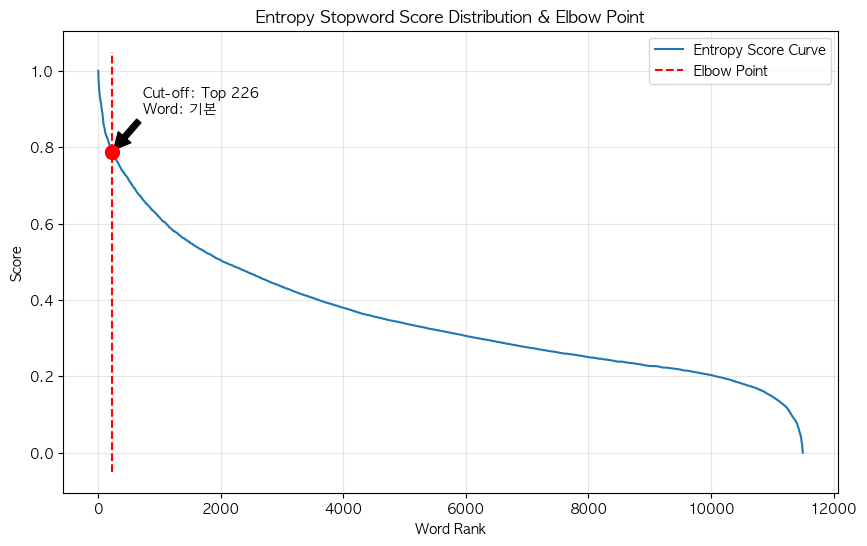


>>> MP-VP 기반 최적 컷오프 탐색...
--------------------------------------------------
[MP-VP] 분석 결과
 >> 추천 Cut-off 순위: Top 54위
 >> 해당 순위 단어: '담당' (점수: 1.0646)
 >> 이 지점까지를 불용어로 간주하면 약 54개의 단어가 선택됩니다.


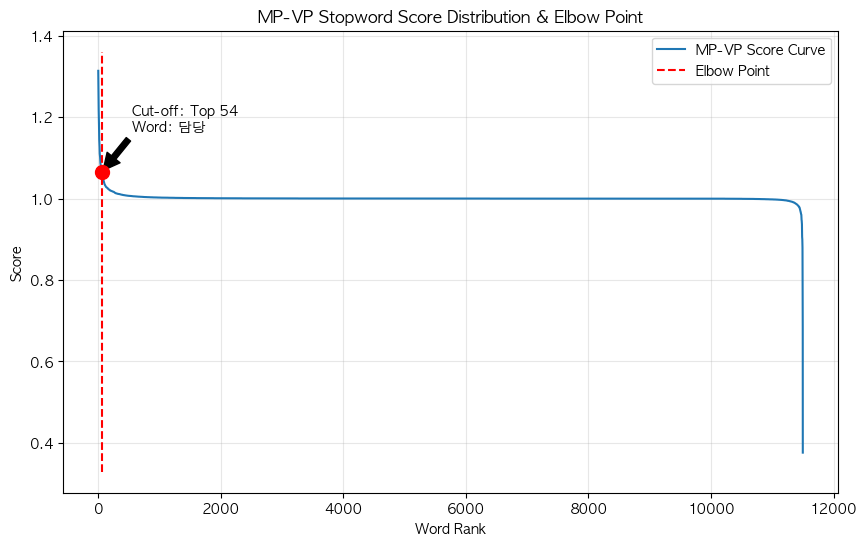


[최종] 엘보우 포인트 기준으로 총 226개의 불용어 후보가 추출되었습니다.
파일 저장 완료: suggested_stopwords_elbow_cutoff.csv


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rc
from kneed import KneeLocator  # pip install kneed
import numpy as np

# 0. 폰트 설정
rc('font', family='AppleGothic') 
plt.rcParams['axes.unicode_minus'] = False  # 마이너스 기호(-)가 깨지는 문제 해결

# 1. 결과 파일 로드
INPUT_FILE = "legal_stopword_analysis_final.csv"
df = pd.read_csv(INPUT_FILE)

# ---------------------------------------------------------
# 함수: 엘보우 포인트 찾기 및 시각화
# ---------------------------------------------------------
def find_and_plot_elbow(df, score_col, method_name):
    # 점수 내림차순 정렬 (높은 점수가 불용어일 확률 높음)
    sorted_df = df.sort_values(by=score_col, ascending=False).reset_index(drop=True)
    
    # X축: 순위 (Rank), Y축: 점수 (Score)
    x = sorted_df.index.tolist()
    y = sorted_df[score_col].tolist()
    
    # Kneedle 알고리즘 적용
    # curve='convex': 볼록한 형태 (점수가 뚝 떨어지는 형태)
    # direction='decreasing': 감소하는 방향
    kneedle = KneeLocator(x, y, curve="convex", direction="decreasing", S=1.0)
    elbow_rank = kneedle.elbow
    
    if elbow_rank is None:
        print(f"[{method_name}] 엘보우 포인트를 찾지 못했습니다. (데이터가 너무 선형적임)")
        return None, None
    
    elbow_value = y[elbow_rank]
    elbow_word = sorted_df.iloc[elbow_rank]['word']
    
    print("-" * 50)
    print(f"[{method_name}] 분석 결과")
    print(f" >> 추천 Cut-off 순위: Top {elbow_rank}위")
    print(f" >> 해당 순위 단어: '{elbow_word}' (점수: {elbow_value:.4f})")
    print(f" >> 이 지점까지를 불용어로 간주하면 약 {elbow_rank}개의 단어가 선택됩니다.")
    
    # 시각화
    plt.figure(figsize=(10, 6))
    plt.plot(x, y, label=f'{method_name} Score Curve')
    plt.vlines(elbow_rank, plt.ylim()[0], plt.ylim()[1], linestyles='dashed', colors='red', label='Elbow Point')
    plt.scatter([elbow_rank], [elbow_value], color='red', s=100, zorder=5)
    
    # 상위 10개 단어 표시 (참고용)
    plt.title(f"{method_name} Stopword Score Distribution & Elbow Point")
    plt.xlabel("Word Rank")
    plt.ylabel("Score")
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # 텍스트 어노테이션
    plt.annotate(f'Cut-off: Top {elbow_rank}\nWord: {elbow_word}', 
                 xy=(elbow_rank, elbow_value), 
                 xytext=(elbow_rank + 500, elbow_value + 0.1),
                 arrowprops=dict(facecolor='black', shrink=0.05))
    
    plt.show()
    
    return elbow_rank, sorted_df.head(elbow_rank)

# ---------------------------------------------------------
# 실행: Entropy와 MP-VP 각각 분석
# ---------------------------------------------------------

# 1. Entropy 기반 엘보우
print(">>> Entropy 기반 최적 컷오프 탐색...")
rank_ent, df_ent = find_and_plot_elbow(df, 'score_entropy', 'Entropy')

# 2. MP-VP 기반 엘보우
print("\n>>> MP-VP 기반 최적 컷오프 탐색...")
rank_mpvp, df_mpvp = find_and_plot_elbow(df, 'score_mpvp', 'MP-VP')

# ---------------------------------------------------------
# 결과 저장 (자동으로 잘린 리스트)
# ---------------------------------------------------------
if rank_ent and rank_mpvp:
    # 두 리스트의 합집합(Union) 생성
    stopword_candidates = set(df_ent['word']).union(set(df_mpvp['word']))
    
    result_df = df[df['word'].isin(stopword_candidates)]
    result_df.to_csv("suggested_stopwords_elbow_cutoff.csv", index=False, encoding='utf-8-sig')
    print(f"\n[최종] 엘보우 포인트 기준으로 총 {len(stopword_candidates)}개의 불용어 후보가 추출되었습니다.")
    print("파일 저장 완료: suggested_stopwords_elbow_cutoff.csv")


>>> 빈도(TF) 기반 Zipf's Law 최적 컷오프 탐색...
--------------------------------------------------
[Frequency(TF)] 분석 결과
 >> 추천 Cut-off 순위: Top 167위
 >> 해당 순위 단어: '잘못' (점수: 0.0636)
 >> 이 지점까지를 불용어로 간주하면 약 167개의 단어가 선택됩니다.


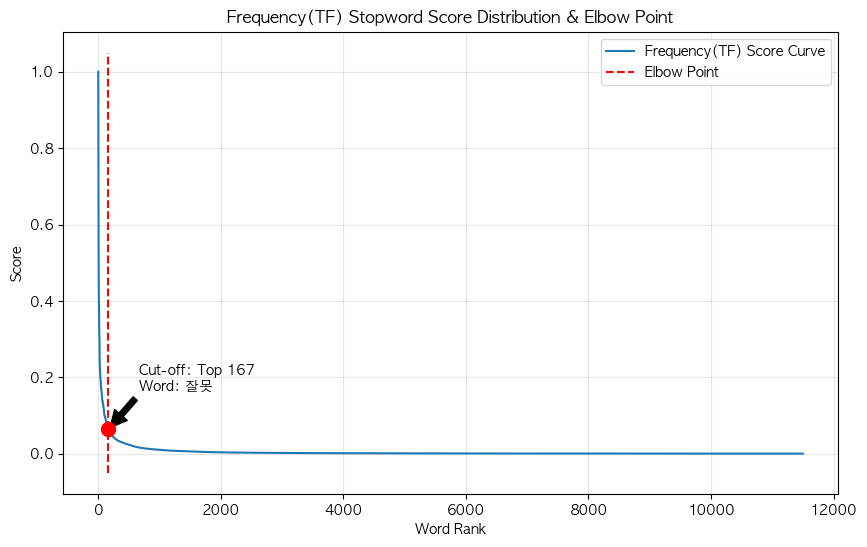

Zipf 기반 추가 후보: ['경우', '따른', '한다', '따라', '사건', '관한', '해당', '조제', '정하', '필요'] ... 등 167개


In [6]:
# ---------------------------------------------------------
# [추가] 단순 빈도(TF) 기반 엘보우 분석 (Zipf's Law Cut-off)
# ---------------------------------------------------------

# 1. 빈도(Count) 기준으로 정렬
df_tf = df.sort_values(by='count', ascending=False).reset_index(drop=True)

# 2. 정규화된 빈도 사용 (그래프 이쁘게 나오라고)
# (이미 norm_count가 없다면 계산)
df_tf['norm_count'] = (df_tf['count'] - df_tf['count'].min()) / (df_tf['count'].max() - df_tf['count'].min())

# 3. 엘보우 찾기
print("\n>>> 빈도(TF) 기반 Zipf's Law 최적 컷오프 탐색...")
# 빈도 그래프는 L자 형태이므로 curve='convex', direction='decreasing'
rank_tf, _ = find_and_plot_elbow(df_tf, 'norm_count', 'Frequency(TF)')

# 4. 결과 해석
if rank_tf:
    stopword_candidates_tf = df_tf.head(rank_tf)['word'].tolist()
    print(f"Zipf 기반 추가 후보: {stopword_candidates_tf[:10]} ... 등 {len(stopword_candidates_tf)}개")

### 불용어 파일 생성

>>> 1. 단순 빈도(Zipf) 기반 추출 중...
[Frequency_Zipf] Cut-off: Top 167위 (점수: 9717.0000)


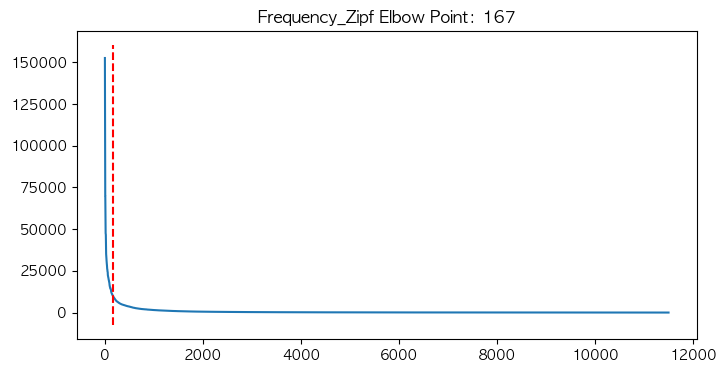

>>> 2. 엔트로피(Entropy) 기반 추출 중...
[Entropy_Randomness] Cut-off: Top 226위 (점수: 0.7885)


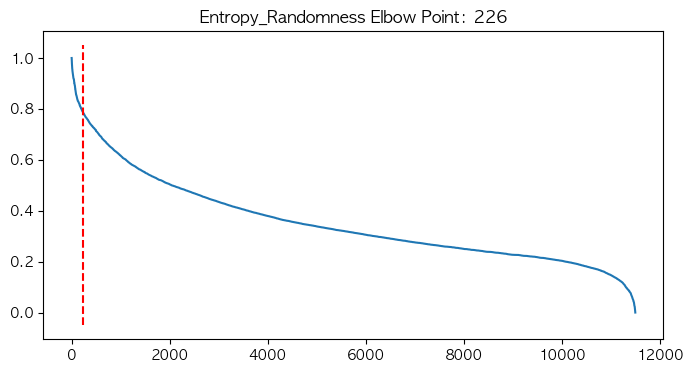

>>> 3. 안정성(MP-VP) 기반 추출 중...
[Stability_MPVP] Cut-off: Top 54위 (점수: 1.0646)


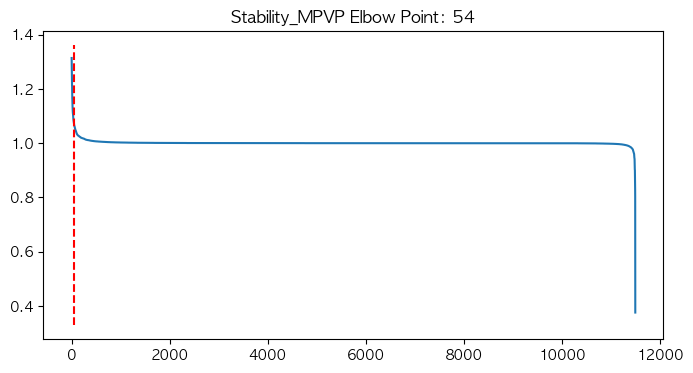

변호사 공유용 엑셀 저장 완료.

>>> 연구 실험용 CSV 파일 분리 저장 중...
 - 실험 A용 (빈도): stopwords_exp_A_zipf.csv (167개)
 - 실험 B용 (엔트로피): stopwords_exp_B_entropy.csv (226개)
 - 실험 C용 (안정성): stopwords_exp_C_mpvp.csv (54개)
 - 실험 D용 (전체 통합): stopwords_exp_D_union.csv (286개)

모든 파일 저장 완료! 이제 LBOX 벤치마크 실험 준비가 끝났습니다.


In [8]:
import pandas as pd
from kneed import KneeLocator
import matplotlib.pyplot as plt
from matplotlib import rc

# 1. 한글 폰트 설정 (Mac)
rc('font', family='AppleGothic')
plt.rcParams['axes.unicode_minus'] = False

# 2. 데이터 로드
INPUT_FILE = "legal_stopword_analysis_final.csv"
df = pd.read_csv(INPUT_FILE)

# ---------------------------------------------------------
# 함수: 엘보우 포인트 계산 및 상위 리스트 반환 (그래프 생략 가능)
# ---------------------------------------------------------
def get_elbow_candidates(df, target_col, method_name, plot=False):
    # 정렬
    sorted_df = df.sort_values(by=target_col, ascending=False).reset_index(drop=True)
    
    x = sorted_df.index.tolist()
    y = sorted_df[target_col].tolist()
    
    # Kneedle 알고리즘
    kneedle = KneeLocator(x, y, curve="convex", direction="decreasing", S=1.0)
    elbow_rank = kneedle.elbow
    
    if elbow_rank is None:
        print(f"[{method_name}] 엘보우 포인트를 찾지 못했습니다. Top 100개로 대체합니다.")
        elbow_rank = 100
    
    cut_off_value = y[elbow_rank]
    candidates = sorted_df.head(elbow_rank).copy()
    candidates['selected_by'] = method_name # 어떤 기법으로 뽑혔는지 태깅
    
    print(f"[{method_name}] Cut-off: Top {elbow_rank}위 (점수: {cut_off_value:.4f})")
    
    if plot:
        plt.figure(figsize=(8, 4))
        plt.plot(x, y, label=f'{method_name} Score')
        plt.vlines(elbow_rank, plt.ylim()[0], plt.ylim()[1], linestyles='dashed', colors='red')
        plt.title(f"{method_name} Elbow Point: {elbow_rank}")
        plt.show()
        
    return candidates

# ---------------------------------------------------------
# 3. 세 가지 관점에서 후보 추출
# ---------------------------------------------------------
print(">>> 1. 단순 빈도(Zipf) 기반 추출 중...")
# count가 클수록 불용어
cand_tf = get_elbow_candidates(df, 'count', 'Frequency_Zipf', plot=True)

print(">>> 2. 엔트로피(Entropy) 기반 추출 중...")
# score_entropy가 클수록 불용어
cand_ent = get_elbow_candidates(df, 'score_entropy', 'Entropy_Randomness', plot=True)

print(">>> 3. 안정성(MP-VP) 기반 추출 중...")
# score_mpvp가 클수록 불용어
cand_mpvp = get_elbow_candidates(df, 'score_mpvp', 'Stability_MPVP', plot=True)

# ... (앞부분의 데이터 로드, 엘보우 계산 로직은 동일) ...

# ---------------------------------------------------------
# 4. 결과 통합 (Union)
# ---------------------------------------------------------
# 세 리스트 합치기 (실험 D용)
all_candidates = pd.concat([cand_tf, cand_ent, cand_mpvp])
final_df = all_candidates.groupby('word').agg({
    'selected_by': lambda x: ', '.join(set(x)), 
    'count': 'first',
    'score_entropy': 'first',
    'score_mpvp': 'first'
}).reset_index().sort_values(by='count', ascending=False)

# ---------------------------------------------------------
# 5. 저장 1: 변호사 공유용 (Excel - 통합본)
# ---------------------------------------------------------
# (이 부분은 동일하게 유지 - 변호사님은 한 번에 보는 게 편하니까)
excel_df = final_df[['word', 'selected_by']].copy()
excel_df.columns = ['단어(형태소)', '추출_알고리즘_근거']
excel_df['추출_알고리즘_근거'] = excel_df['추출_알고리즘_근거'].replace({
    'Frequency_Zipf': '고빈도 단어',
    'Entropy_Randomness': '구조적 불용어',
    'Stability_MPVP': '기능적 불용어'
}, regex=True)
excel_df['삭제여부(O/X)'] = '' 
excel_df['비고(의견)'] = ''

with pd.ExcelWriter("불용어_후보_검토요청서.xlsx") as writer:
    excel_df.to_excel(writer, sheet_name='종합_후보_목록', index=False)
    cand_tf.to_excel(writer, sheet_name='참고_빈도기반', index=False)
    cand_ent.to_excel(writer, sheet_name='참고_엔트로피', index=False)
    cand_mpvp.to_excel(writer, sheet_name='참고_안정성', index=False)
print("변호사 공유용 엑셀 저장 완료.")

# ---------------------------------------------------------
# 6. 저장 2: 연구자용 (CSV - 실험용 분리 저장)
# ---------------------------------------------------------
print("\n>>> 연구 실험용 CSV 파일 분리 저장 중...")

# [실험 A] Zipf(빈도) 기반
file_a = "stopwords_exp_A_zipf.csv"
cand_tf.to_csv(file_a, index=False, encoding='utf-8-sig')
print(f" - 실험 A용 (빈도): {file_a} ({len(cand_tf)}개)")

# [실험 B] Entropy 기반
file_b = "stopwords_exp_B_entropy.csv"
cand_ent.to_csv(file_b, index=False, encoding='utf-8-sig')
print(f" - 실험 B용 (엔트로피): {file_b} ({len(cand_ent)}개)")

# [실험 C] MP-VP(안정성) 기반
file_c = "stopwords_exp_C_mpvp.csv"
cand_mpvp.to_csv(file_c, index=False, encoding='utf-8-sig')
print(f" - 실험 C용 (안정성): {file_c} ({len(cand_mpvp)}개)")

# [실험 D] Union (합집합)
file_d = "stopwords_exp_D_union.csv"
final_df.to_csv(file_d, index=False, encoding='utf-8-sig')
print(f" - 실험 D용 (전체 통합): {file_d} ({len(final_df)}개)")

print("\n모든 파일 저장 완료! 이제 LBOX 벤치마크 실험 준비가 끝났습니다.")